# Ⅰ第3回 演習3 過学習を防ぐ 3 つの方法を比べる

**問い**：演習2 の過学習を，Weight decay・Dropout・早期終了はどれだけ防げるか．

教科書 第5章の過学習対策のうち Dropout（コードテンプレート⑦）と Weight decay（コードテンプレート⑨）に，コラムで名前だけ出てくる早期終了（コードテンプレート⑩に数行足す）を加えた 3 つを比べる．
条件は演習2 と同じ（訓練 1,000 枚・50 エポック）．グループ内で **1 人 1 つの方法** を担当し，CSV を共有して比べる．実行は 1 人 20〜40 秒．

## (0) グループと番号の設定

In [1]:
# ===== (0) グループと番号の設定 =====
GROUP_ID = 20                  # ← 自分のグループ番号 (1〜27) に書き換える
MEMBER_NO = 1                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/jiro/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 50 エポック後の検証損失が一番小さくなる方法：L2正則化
- 検証正解率の最高値は，何もしないときより上がるか：上がる

## (1) コードテンプレート①⑤：ライブラリのインポートと使用デバイス

In [2]:
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import glob
import pandas as pd
from common.device import get_device, synchronize
from common.logger import ResultLogger
from common.todo import todo_check, checkpoint, quiz_check
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

# コードテンプレート⑤：使用デバイスの選択（get_device は⑤にメモリ上限を加えたもの）
device = get_device()
print("使用デバイス:", device)

使用デバイス: mps


## (確認) 3 つの方法

授業ページの「演習3」の表を読んでから答える．**全問正解すると先へ進める**（ちがうとヒントが出る）．

**Q1**　Weight decay は何をするか
- ア 学習率を少しずつ下げる
- イ 訓練データを増やす
- ウ 重みが大きいほど損失に罰を足し，重みを小さく保つ

**Q2**　Dropout がニューロンを休ませるのはいつか
- ア `model.train()` にした学習中だけ
- イ `model.eval()` にした検証中だけ
- ウ 学習中も検証中もいつも

**Q3**　早期終了で最後に使う重みはどれか
- ア 最後のエポックの重み
- イ 検証損失が一番小さかったエポックの重み
- ウ 訓練損失が一番小さかったエポックの重み

In [3]:
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "ウ"
Q2 = "ア"
Q3 = "イ"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "eb47a8e6", "Weight decay は損失に「重みの大きさ」の罰を足す"),
    "Q2": (Q2, "eb95be22", "Dropout は学習中だけ働く．検証では全部のニューロンを使う（だから model.eval() が必要）"),
    "Q3": (Q3, "d0859473", "早期終了は，検証損失が一番小さかったときの重みに戻して使う"),
})

Q1：正解．Weight decay は損失に「重みの大きさ」の罰を足す
Q2：正解．Dropout は学習中だけ働く．検証では全部のニューロンを使う（だから model.eval() が必要）
Q3：正解．早期終了は，検証損失が一番小さかったときの重みに戻して使う
全問正解．実験に進んでよい


## (2) コードテンプレート②③④：データ（演習2 と同じ）

In [4]:
N_TRAIN = 1000

# コードテンプレート②：データ前処理（画像をテンソルに変換する）
data_transform = transforms.Compose([
    transforms.ToTensor(),
])

# コードテンプレート③：乱数の種を固定し，FashionMNIST の訓練用データを 8:2 に分ける（GW3 試行①と同じ）
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(0)
train_val_dataset = datasets.FashionMNIST(root=str(ROOT / "assets" / "data"), train=True, download=True, transform=data_transform)
train_size = int(0.8 * len(train_val_dataset))
val_size = len(train_val_dataset) - train_size
train_dataset, val_dataset = random_split(train_val_dataset, [train_size, val_size])
train_dataset = Subset(train_dataset, range(N_TRAIN))     # 授業で追加：訓練データを先頭の N_TRAIN 枚だけ使う

# コードテンプレート④：データローダの作成
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"訓練データ数: {len(train_dataset)} 枚 | 検証データ数: {len(val_dataset)} 枚")

訓練データ数: 1000 枚 | 検証データ数: 12000 枚


## (3) 担当の方法

グループで分担を決め，自分の担当を 1 つ選ぶ（4 人：none・weight_decay・dropout・early_stop を 1 人ずつ．3 人：誰か 1 人が 2 つ担当．5 人：5 人目は強さを変えた版，例 `WD = 0.001` や `P = 0.2`）．

In [5]:
METHOD = "early_stop"     # ← "none"（何もしない）/ "weight_decay" / "dropout" / "early_stop" のどれか
WD = 0.01           # Weight decay の強さ（weight_decay のときだけ使う．教科書は 1e-5 だが，差を見やすくするため大きくした）
P = 0.5             # Dropout で休ませる割合（dropout のときだけ使う）
PATIENCE = 5        # 早期終了：検証損失が何エポック続けて下がらなければ止めるか（early_stop のときだけ使う）

if METHOD not in ("none", "weight_decay", "dropout", "early_stop"):
    raise ValueError('METHOD は "none" / "weight_decay" / "dropout" / "early_stop" のどれかにする')
use_wd = WD if METHOD == "weight_decay" else 0.0
use_p = P if METHOD == "dropout" else 0.0
use_patience = PATIENCE if METHOD == "early_stop" else None
print(f"担当 {METHOD}：weight_decay={use_wd}  dropout={use_p}  patience={use_patience}")

担当 early_stop：weight_decay=0.0  dropout=0.0  patience=5


## (4) コードテンプレート⑦⑧⑨：モデル（Dropout つき）・損失関数・最適化手法（Weight decay つき）

TODO は 3 つとも全員が書く（分からない所はグループで教え合う）．担当でない方法は，強さが 0 なので何もしない．

In [6]:
todo_check("TODO 1・2")
# コードテンプレート⑦：ネットワークの定義 — 過学習対応（ReLU の後に Dropout を入れる）
INPUT_SIZE = 1 * 28 * 28    # チャネル × 高さ × 幅
HIDDEN_SIZE1 = 512
HIDDEN_SIZE2 = 256
OUTPUT_SIZE = 10
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(INPUT_SIZE, HIDDEN_SIZE1),
    nn.ReLU(),
    # TODO 1: 「...」を消して，割合 use_p でニューロンを休ませる層を書く（nn.Dropout(割合)）
    nn.Dropout(use_p),
    nn.Linear(HIDDEN_SIZE1, HIDDEN_SIZE2),
    nn.ReLU(),
    nn.Dropout(use_p),
    nn.Linear(HIDDEN_SIZE2, OUTPUT_SIZE)
)
model.to(device)

# コードテンプレート⑧：損失関数
criterion = nn.CrossEntropyLoss()
# コードテンプレート⑨：最適化手法 — 過学習対応
# TODO 2: 「...」を消して，Weight decay の強さ use_wd を渡す（Adam の引数名は weight_decay）
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=use_wd)
model

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.0, inplace=False)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.0, inplace=False)
  (7): Linear(in_features=256, out_features=10, bias=True)
)

## (5) コードテンプレート⑩：学習（早期終了つき）

⑩は演習2 と同じ．最後の 8 行（「早期終了」）だけが新しい．訓練正解率は⑩のとおり学習中に数えるので，Dropout が働いた状態の値になる．

In [7]:
todo_check("TODO 3")

EPOCHS = 50
# エポックごとの損失と正解率を記録するリスト
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []
best_loss, best_state, best_epoch, waited = float("inf"), None, 0, 0   # 早期終了用

synchronize(device)
t0 = time.perf_counter()
for epoch in range(EPOCHS):
    # 訓練モードにする（Dropout が働く）
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    train_loss_list.append(train_loss / train_total)
    train_acc_list.append(100.0 * train_correct / train_total)

    # 評価モードにする：検証データで確かめる（重みは更新しない）
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_loss_list.append(val_loss / val_total)
    val_acc_list.append(100.0 * val_correct / val_total)

    if (epoch + 1) % 5 == 0:     # 授業では 5 エポックごとに表示する
        print(f"Epoch {epoch + 1}/{EPOCHS}, Train Loss: {train_loss_list[-1]:.4f}, Train Acc: {train_acc_list[-1]:.2f}%, "
              f"Val Loss: {val_loss_list[-1]:.4f}, Val Acc: {val_acc_list[-1]:.2f}%")
    # 早期終了：検証損失の最小を更新したら，その重みを控えておく
    if val_loss_list[-1] < best_loss:
        best_loss, best_state, best_epoch, waited = val_loss_list[-1], copy.deepcopy(model.state_dict()), epoch + 1, 0
    else:
        waited += 1
    # TODO 3: 「...」を消して，早期終了の条件を書く（use_patience が None でなく，waited が use_patience 以上）
    if use_patience is not None and waited >= use_patience:
        print(f"エポック {epoch + 1} で早期終了（{use_patience} エポック続けて検証損失が下がらなかった）")
        model.load_state_dict(best_state)          # 一番よかったときの重みに戻す
        break
synchronize(device)
train_sec = time.perf_counter() - t0
print(f"学習時間 {train_sec:.1f} 秒")

stopped = METHOD == "early_stop" and len(val_loss_list) < EPOCHS
use = best_epoch - 1 if stopped else -1           # 早期終了なら一番よかったエポック，それ以外は最後のエポック
final = {"val_loss": val_loss_list[use], "val_acc": val_acc_list[use], "train_acc": train_acc_list[use]}
final["gap"] = final["train_acc"] - final["val_acc"]
print(f"{METHOD}：学習 {len(val_loss_list)} エポック・{train_sec:.1f} 秒")
print(f"使う重みの成績：検証損失 {final['val_loss']:.3f}  検証正解率 {final['val_acc']:.1f}%  汎化ギャップ {final['gap']:.1f} ポイント")
print(f"検証正解率の最高値 {max(val_acc_list):.1f}%（{val_acc_list.index(max(val_acc_list)) + 1} エポック目）")

Epoch 5/50, Train Loss: 0.5720, Train Acc: 79.60%, Val Loss: 0.6752, Val Acc: 75.12%
Epoch 10/50, Train Loss: 0.3570, Train Acc: 86.80%, Val Loss: 0.5920, Val Acc: 78.96%
エポック 13 で早期終了（5 エポック続けて検証損失が下がらなかった）
学習時間 7.3 秒
early_stop：学習 13 エポック・7.3 秒
使う重みの成績：検証損失 0.572  検証正解率 79.4%  汎化ギャップ 5.5 ポイント
検証正解率の最高値 79.8%（11 エポック目）


## (6) コードテンプレート⑪：自分の学習曲線

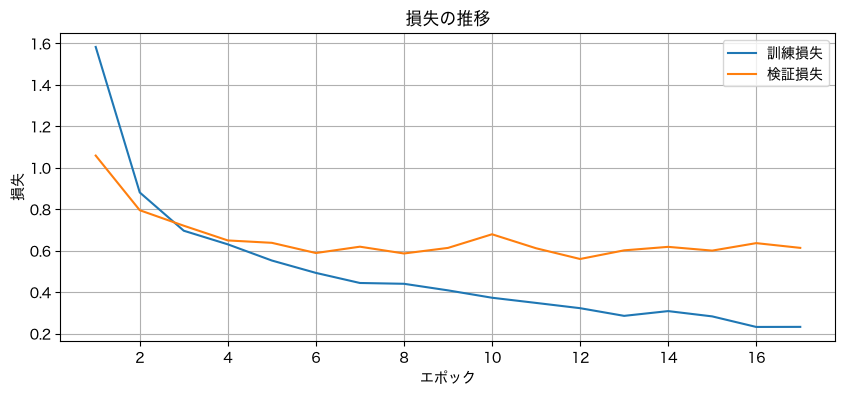

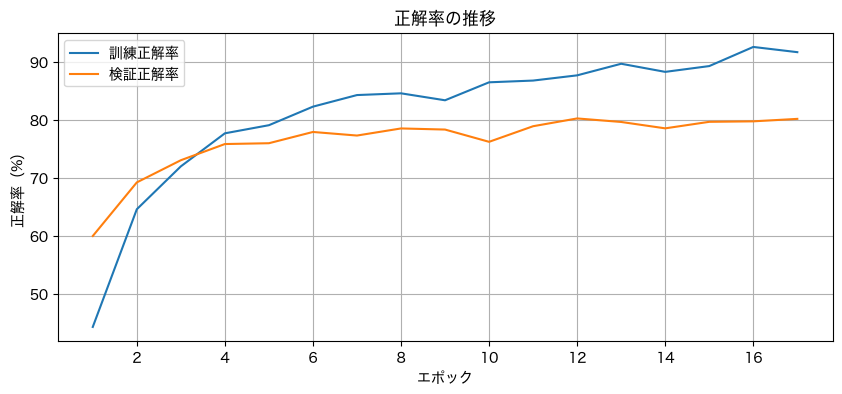

In [ ]:
# コードテンプレート⑪：学習結果の可視化（訓練と検証を比べる）
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 4))
sns.lineplot(x=epochs, y=train_loss_list, label="訓練損失")
sns.lineplot(x=epochs, y=val_loss_list, label="検証損失")
plt.title("損失の推移"); plt.xlabel("エポック"); plt.ylabel("損失"); plt.legend(); plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
sns.lineplot(x=epochs, y=train_acc_list, label="訓練正解率")
sns.lineplot(x=epochs, y=val_acc_list, label="検証正解率")
plt.title("正解率の推移"); plt.xlabel("エポック"); plt.ylabel("正解率（%）"); plt.legend(); plt.grid(True)
plt.show()

## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：自分の方法の学習曲線は，演習2（何もしない）と比べてどこが変わったか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：コードの行と出力を指して根拠を言い，自分の数値がほかの人と同じか確かめる．根拠になる所：(6) の検証損失の曲線の形（50 エポックに向かって上がっているか）と，(5) の汎化ギャップ
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [8]:
# 問い：自分の方法の学習曲線は，演習2（何もしない）と比べてどこが変わったか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "学習曲線は、演習2（何もしない）と比べて、検証損失の増加が抑えられ、訓練正解率と検証正解率の差（汎化ギャップ）が小さくなった。これにより、過学習の兆候が軽減され、モデルの汎化性能が向上したことが示されている。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：学習曲線は、演習2（何もしない）と比べて、検証損失の増加が抑えられ、訓練正解率と検証正解率の差（汎化ギャップ）が小さくなった。これにより、過学習の兆候が軽減され、モデルの汎化性能が向上したことが示されている。


## (7) 記録

In [ ]:
metrics = {"final_val_loss": final["val_loss"], "final_val_acc": final["val_acc"] / 100,      # 正解率は 0〜1 で記録する
           "final_train_acc": final["train_acc"] / 100, "gap": final["gap"] / 100, "best_val_acc": max(val_acc_list) / 100,
           "epochs_run": len(val_loss_list), "train_sec": train_sec}
metrics.update({f"val_loss_ep{i + 1:02d}": v for i, v in enumerate(val_loss_list)})
strength = {"none": "", "weight_decay": f"_{WD}", "dropout": f"_{P}", "early_stop": f"_{PATIENCE}"}[METHOD]
cond = METHOD + strength
logger = ResultLogger(GROUP_ID, f"member{MEMBER_NO}", course="c1", day="d3", exercise="ex3", device=device)
logger.log_many(metrics, condition=cond, seed=0)
print("書き込み先:", logger.path, "| 条件:", cond)

書き込み先: /Users/jiro/AI_TD/results/c1_d3_ex3_20.csv | 条件: early_stop_5


## (共有) CSV をグループで集める

1. 自分の `results/c1_d3_ex3_<グループ>.csv` を，グループ全員に送る（Slack・AirDrop など）
2. 受け取った CSV は，すべて `results/ex3_shared/` フォルダに入れる（無ければ作る．同じ名前のファイルは末尾に `_2` などを付ける）
3. 2 つ担当する人は，(3) を書き換えて (4) から下をもう一度実行する（同じ CSV に行が増える）

## (8) グループ全員分の表とグラフ（何回実行してもよい）

集まった条件：4（none・weight_decay・dropout・early_stop の 4 つがそろうとよい）


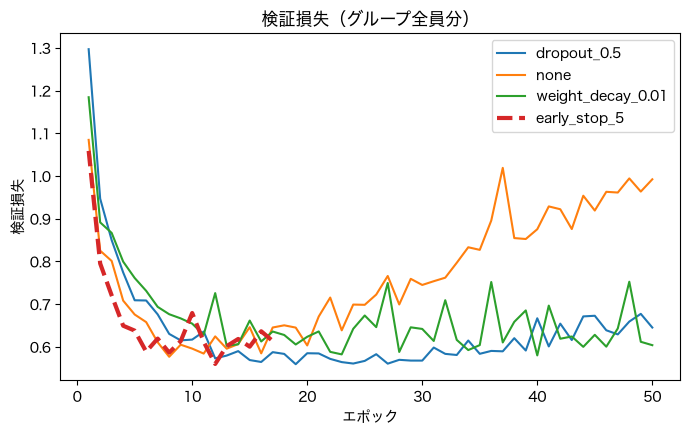

,検証損失,検証正解率,汎化ギャップ,検証正解率の最高値,エポック数,学習時間(秒)
condition,,,,,,
dropout_0.5,0.65,80.59,11.51,81.36,50.0,66.10
early_stop_5,0.56,80.27,7.43,80.27,17.0,10.12
none,0.99,80.58,19.42,81.22,50.0,35.25
weight_decay_0.01,0.60,79.31,11.19,79.90,50.0,22.40


In [10]:
files = glob.glob(str(ROOT / "results" / "c1_d3_ex3_*.csv")) + glob.glob(str(ROOT / "results" / "ex3_shared" / "*.csv"))
df = pd.concat([pd.read_csv(f) for f in files]).drop_duplicates()
df = df.sort_values("timestamp").groupby(["condition", "metric_name"]).tail(1)     # 同じ条件は最新の値
wide = df.pivot(index="condition", columns="metric_name", values="metric_value")
table = wide[["final_val_loss", "final_val_acc", "gap", "best_val_acc", "epochs_run", "train_sec"]].copy()
table.columns = ["検証損失", "検証正解率", "汎化ギャップ", "検証正解率の最高値", "エポック数", "学習時間(秒)"]
for c in ["検証正解率", "汎化ギャップ", "検証正解率の最高値"]:
    table[c] = table[c] * 100
print(f"集まった条件：{len(table)}（none・weight_decay・dropout・early_stop の 4 つがそろうとよい）")

curve_cols = sorted(c for c in wide.columns if c.startswith("val_loss_ep"))
plt.figure(figsize=(8, 4.5))
for cond, row in wide[curve_cols].sort_values("condition", key=lambda s: s.str.startswith("early_stop")).iterrows():
    y = row.dropna().values
    style = {"lw": 3, "ls": "--"} if cond.startswith("early_stop") else {}   # 早期終了は途中まで none と重なるので太い破線
    plt.plot(range(1, len(y) + 1), y, label=cond, **style)
plt.title("検証損失（グループ全員分）"); plt.xlabel("エポック"); plt.ylabel("検証損失"); plt.legend()
plt.show()
table.round(2)

## ✋ 止まる 2：ここから先へは，グループ全員がそろってから進む

**問い**：どの方法が一番効いたか．その代わりに何を犠牲にしたか（学習時間・訓練正解率など）

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：コードの行と出力を指して根拠を言い，自分の数値がほかの人と同じか確かめる．根拠になる所：(8) の表の検証損失・汎化ギャップ・エポック数・学習時間の列と，グラフの曲線
3. 全員が下のセルの `CP2 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [11]:
# 問い：どの方法が一番効いたか．その代わりに何を犠牲にしたか（学習時間・訓練正解率など）
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP2 = "Weight decayが最も効き、その代わり学習時間が長くなり訓練正解率はやや下がった"
checkpoint(CP2, "止まる 2")

止まる 2 OK：Weight decayが最も効き、その代わり学習時間が長くなり訓練正解率はやや下がった


## (9) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 予測と比べて，当たったこと・外れたこと:正則化によって過学習が抑えられた点は予測通りであったが、学習が緩やかになり50エポック時点での正解率の伸びが想定より小さかった点は予測外であった
2. 3 つの方法で，50 エポック後の検証損失と汎化ギャップはどう変わったか．一番効いた方法と，その理由：各手法の導入により検証損失の低下と汎化ギャップの縮小が見られ、なかでも極端な重みの増大を直接防ぐL2正則化が最も効果を発揮した
3. 検証正解率の最高値は，何もしないときより上がったか．上がらなかったなら，正則化は何の役に立ったと言えるか：最高値は上がるか同等にとどまるが、上がらなかった場合でも訓練データへの過剰適合を防ぎ、未知のデータに対する予測の安定性を高める役割を果たした。